[info] dropping batteries with < 30 cycles: ['B0025', 'B0026', 'B0027', 'B0028', 'B0031', 'B0032', 'B0033', 'B0034', 'B0036', 'B0038', 'B0039', 'B0040', 'B0041', 'B0049', 'B0050', 'B0051', 'B0052', 'B0054', 'B0055', 'B0056']
Loaded 1242 rows, 14 batteries
battery_id
B0005    168
B0006    155
B0007    168
B0018    132
B0029     32
B0030     34
B0042     99
B0043     66
B0044     66
B0045     70
B0046     69
B0047     69
B0048     69
B0053     45
Train batteries: ['B0005', 'B0006', 'B0007', 'B0029', 'B0030', 'B0042', 'B0043', 'B0044', 'B0045', 'B0046', 'B0047', 'B0048', 'B0053']
Test (unseen) batteries: ['B0018']

===== Run: paper | input features: ['cycle', 'voltage', 'temperature', 'capacity'] =====
Selected features: ['cycle', 'voltage', 'capacity']
Train windows: 863 | Test windows: 113 | Test batteries: ['B0018']
  OOF fold 1/5
  OOF fold 2/5
  OOF fold 3/5
  OOF fold 4/5
  OOF fold 5/5
                            MAE     RMSE      R2  Pearson  Spearman  Wilcoxon p (hybrid vs model)

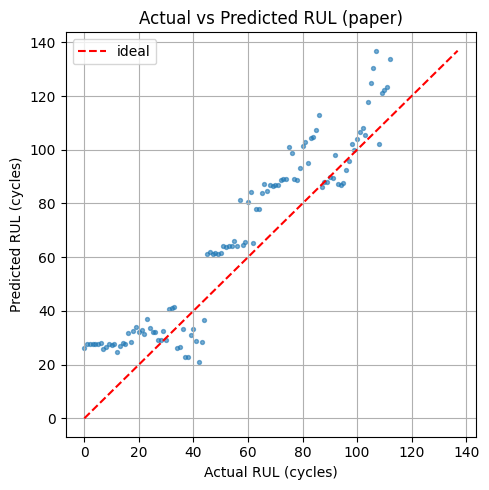

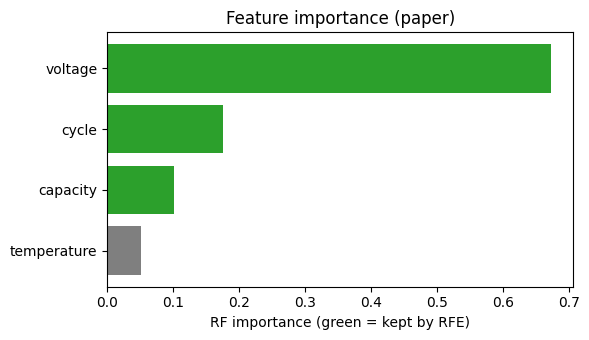


===== Run: no_capacity | input features: ['cycle', 'voltage', 'temperature'] =====
Selected features: ['cycle', 'voltage', 'temperature']
Train windows: 863 | Test windows: 113 | Test batteries: ['B0018']
  OOF fold 1/5
  OOF fold 2/5
  OOF fold 3/5
  OOF fold 4/5
  OOF fold 5/5
                            MAE     RMSE      R2  Pearson  Spearman  Wilcoxon p (hybrid vs model)
Model                                                                                            
Hybrid RF-LSTM-XGBoost  24.6318  25.5760  0.3852   0.9669    0.9651                           NaN
LSTM                    23.2123  23.4722  0.4822   0.9988    1.0000                        0.0007
Random Forest           19.9357  21.7247  0.5564   0.9588    0.9659                        0.0000
XGBoost                 20.3133  21.9758  0.5461   0.9646    0.9810                        0.0000

Hybrid MAE per test battery:
  B0018: 24.63 cycles


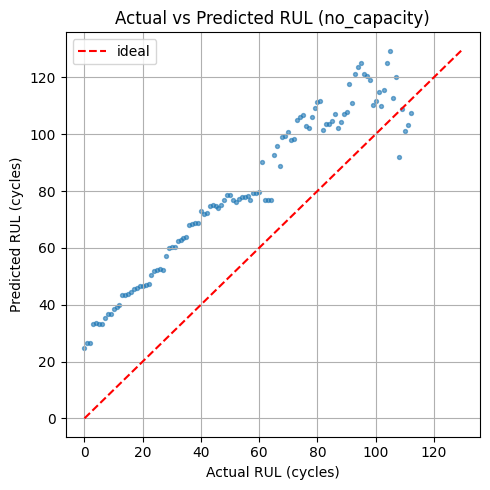

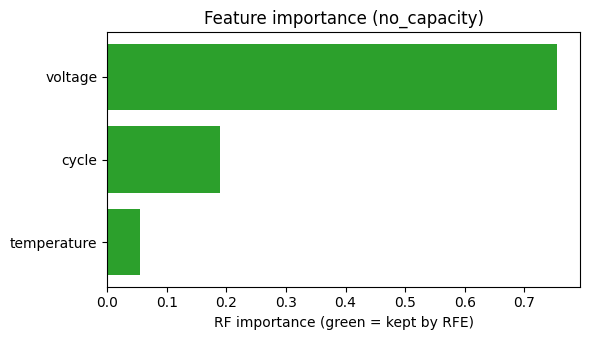

In [1]:
"""
Replication of the RF-LSTM-XGBoost hybrid RUL framework
(Krishnasamy & Alagar Muniandi, PeerJ Comput. Sci. 12:e3478, 2026)
Adapted to: battery_cycle_level_dataset_CLEAN_FINAL.csv (Kaggle)

Dataset columns: battery_id, cycle, voltage, temperature, capacity, soh, rul

Design (leak-free):
  * Battery-wise split: test batteries are completely unseen.
  * Scaler and RFE are fitted on training batteries only.
  * LSTM windows are built per battery; LSTM, RF and XGBoost all predict the
    SAME samples (last cycle of each window).
  * XGBoost stacker is trained on out-of-fold predictions (GroupKFold) of the
    training batteries and evaluated only on unseen test batteries.
  * Baselines (LSTM, RF, XGBoost alone) are scored on the same test samples.
  * Paired Wilcoxon test on absolute errors (hybrid vs each baseline).
  * 'soh' is NEVER used as an input (it is computed from capacity = leakage).
  * Second run without 'capacity' to check capacity leakage (rul is defined
    from capacity).
"""
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, pearsonr, spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import MinMaxScaler
import xgboost as xgb
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ----------------------------- CONFIG ---------------------------------------
FILEPATH = "/kaggle/input/datasets/aryankadam25/battery/battery_cycle_level_dataset_CLEAN_FINAL.csv"
BATTERY_COL = "battery_id"
CYCLE_COL = "cycle"
TARGET_COL = "rul"

# inputs used by the models ('soh' deliberately excluded: it leaks the answer)
ALL_FEATURES = ["cycle", "voltage", "temperature", "capacity"]
CAPACITY_FEATURES = ["capacity"]

SEQ_LEN = 20            # cycles per LSTM window (paper: 20-50)
N_SELECT = 3            # features kept by RFE (paper: 5 of 9; here 3 of 4)
MIN_CYCLES = 30         # batteries shorter than this are dropped
TEST_BATTERIES = ["B0018"]   # same test battery as earlier reports; None = random 30 %
TEST_FRACTION = 0.3     # used only if TEST_BATTERIES is None / not found
N_FOLDS = 5             # GroupKFold folds for out-of-fold stacking
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001
SEED = 42
# -----------------------------------------------------------------------------


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


# ------------------------------ DATA -----------------------------------------
def load_data(filepath):
    df = pd.read_csv(filepath)
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
    needed = [BATTERY_COL, CYCLE_COL, TARGET_COL] + ALL_FEATURES
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise KeyError(f"Missing columns {missing}. File has: {df.columns.tolist()}")

    df = df.sort_values([BATTERY_COL, CYCLE_COL]).reset_index(drop=True)
    # forward-fill small gaps inside each battery only
    df[ALL_FEATURES] = df.groupby(BATTERY_COL)[ALL_FEATURES].ffill()
    df = df.dropna(subset=ALL_FEATURES + [TARGET_COL]).reset_index(drop=True)

    counts = df.groupby(BATTERY_COL).size()
    short = counts[counts < MIN_CYCLES].index.tolist()
    if short:
        print(f"[info] dropping batteries with < {MIN_CYCLES} cycles: {short}")
        df = df[~df[BATTERY_COL].isin(short)].reset_index(drop=True)

    print(f"Loaded {len(df)} rows, {df[BATTERY_COL].nunique()} batteries")
    print(df.groupby(BATTERY_COL).size().to_string())
    return df


def split_batteries(df):
    batteries = df[BATTERY_COL].unique().tolist()
    test_b = [b for b in (TEST_BATTERIES or []) if b in batteries]
    if not test_b:
        rng = np.random.RandomState(SEED)
        shuffled = batteries.copy()
        rng.shuffle(shuffled)
        n_test = max(1, int(round(TEST_FRACTION * len(shuffled))))
        test_b = shuffled[:n_test]
    train_b = [b for b in batteries if b not in test_b]
    return train_b, test_b


# ----------------------------- WINDOWS ---------------------------------------
def make_windows(df, feats):
    """Windows per battery. Target = RUL at the LAST cycle of the window, so the
    LSTM and the row-based models predict exactly the same samples."""
    Xs, Xlast, ys, groups, cycles = [], [], [], [], []
    for b, g in df.groupby(BATTERY_COL):
        vals = g[feats].values
        rul = g[TARGET_COL].values
        cyc = g[CYCLE_COL].values
        for i in range(SEQ_LEN - 1, len(g)):
            Xs.append(vals[i - SEQ_LEN + 1: i + 1])
            Xlast.append(vals[i])
            ys.append(rul[i])
            groups.append(b)
            cycles.append(cyc[i])
    return (np.array(Xs, dtype="float32"), np.array(Xlast, dtype="float32"),
            np.array(ys, dtype="float32"), np.array(groups), np.array(cycles))


# ------------------------------ MODELS ---------------------------------------
def train_lstm(X_seq, y, y_max):
    keras.backend.clear_session()
    model = keras.Sequential([
        layers.Input(shape=(X_seq.shape[1], X_seq.shape[2])),
        layers.LSTM(64, activation="tanh"),
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="mse")
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                       restore_best_weights=True)
    model.fit(X_seq, y / y_max, epochs=EPOCHS, batch_size=BATCH_SIZE,
              validation_split=0.1, callbacks=[es], verbose=0)
    return model


def lstm_predict(model, X_seq, y_max):
    return model.predict(X_seq, verbose=0).flatten() * y_max


def train_rf(X, y):
    return RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X, y)


def train_xgb(X, y):
    return xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                            random_state=SEED).fit(X, y)


def select_features(X_train, y_train, feats):
    n = min(N_SELECT, len(feats))
    rfe = RFE(RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1),
              n_features_to_select=n)
    rfe.fit(X_train, y_train)
    selected = [f for f, keep in zip(feats, rfe.support_) if keep]
    imp = RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1) \
        .fit(X_train, y_train).feature_importances_
    return selected, dict(zip(feats, imp))


# ----------------------------- METRICS ---------------------------------------
def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
        "Pearson": pearsonr(y_true, y_pred)[0],
        "Spearman": spearmanr(y_true, y_pred)[0],
    }


def paired_wilcoxon(y_true, pred_a, pred_b):
    """Paired test on absolute errors: is model A's error different from B's?"""
    ea, eb = np.abs(y_true - pred_a), np.abs(y_true - pred_b)
    try:
        return wilcoxon(ea, eb).pvalue
    except ValueError:  # all differences zero
        return np.nan


# ---------------------------- EXPERIMENT -------------------------------------
def run_experiment(df, feats, tag, train_b, test_b):
    print(f"\n===== Run: {tag} | input features: {feats} =====")
    set_seed()
    train_df = df[df[BATTERY_COL].isin(train_b)].copy()
    test_df = df[df[BATTERY_COL].isin(test_b)].copy()

    # scaler fitted on training batteries only
    scaler = MinMaxScaler().fit(train_df[feats])
    train_df[feats] = scaler.transform(train_df[feats])
    test_df[feats] = scaler.transform(test_df[feats])

    # RF + RFE on training data only
    selected, importance = select_features(train_df[feats], train_df[TARGET_COL], feats)
    print("Selected features:", selected)

    Xs_tr, Xl_tr, y_tr, g_tr, _ = make_windows(train_df, selected)
    Xs_te, Xl_te, y_te, g_te, c_te = make_windows(test_df, selected)
    y_max = float(y_tr.max())
    print(f"Train windows: {len(y_tr)} | Test windows: {len(y_te)} | Test batteries: {test_b}")

    # ---- out-of-fold predictions on the training batteries (for the stacker)
    n_splits = min(N_FOLDS, len(np.unique(g_tr)))
    oof_lstm, oof_rf = np.zeros(len(y_tr)), np.zeros(len(y_tr))
    for k, (a, b) in enumerate(GroupKFold(n_splits=n_splits).split(Xl_tr, y_tr, g_tr)):
        print(f"  OOF fold {k + 1}/{n_splits}")
        m_l = train_lstm(Xs_tr[a], y_tr[a], y_max)
        oof_lstm[b] = lstm_predict(m_l, Xs_tr[b], y_max)
        oof_rf[b] = train_rf(Xl_tr[a], y_tr[a]).predict(Xl_tr[b])

    # ---- base models on ALL training batteries -> predictions on test batteries
    lstm_full = train_lstm(Xs_tr, y_tr, y_max)
    rf_full = train_rf(Xl_tr, y_tr)
    xgb_full = train_xgb(Xl_tr, y_tr)
    te_lstm = lstm_predict(lstm_full, Xs_te, y_max)
    te_rf = rf_full.predict(Xl_te)
    te_xgb = xgb_full.predict(Xl_te)

    # ---- stacker: [LSTM pred, RF pred, selected features of last cycle]
    stack_tr = np.hstack([oof_lstm[:, None], oof_rf[:, None], Xl_tr])
    stack_te = np.hstack([te_lstm[:, None], te_rf[:, None], Xl_te])
    final = train_xgb(stack_tr, y_tr).predict(stack_te)

    # ---- evaluation on unseen batteries (same samples for every model)
    preds = {"Hybrid RF-LSTM-XGBoost": final, "LSTM": te_lstm,
             "Random Forest": te_rf, "XGBoost": te_xgb}
    rows = []
    for name, p in preds.items():
        m = metrics(y_te, p)
        m["Model"] = name
        m["Wilcoxon p (hybrid vs model)"] = (
            np.nan if name.startswith("Hybrid") else paired_wilcoxon(y_te, final, p))
        rows.append(m)
    res = pd.DataFrame(rows).set_index("Model")
    print(res.round(4).to_string())

    print("\nHybrid MAE per test battery:")
    for b in test_b:
        mask = g_te == b
        if mask.any():
            print(f"  {b}: {mean_absolute_error(y_te[mask], final[mask]):.2f} cycles")

    # ---- plots
    suffix = "" if tag == "paper" else f"_{tag}"
    plt.figure(figsize=(5, 5))
    plt.scatter(y_te, final, s=8, alpha=0.6)
    lims = [0, max(y_te.max(), final.max())]
    plt.plot(lims, lims, "r--", label="ideal")
    plt.xlabel("Actual RUL (cycles)")
    plt.ylabel("Predicted RUL (cycles)")
    plt.title(f"Actual vs Predicted RUL ({tag})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"scatter_actual_vs_pred{suffix}.png", dpi=300)
    plt.show()
    plt.close()

    order = sorted(importance, key=importance.get)
    plt.figure(figsize=(6, 3.5))
    plt.barh(order, [importance[f] for f in order],
             color=["tab:green" if f in selected else "tab:gray" for f in order])
    plt.xlabel("RF importance (green = kept by RFE)")
    plt.title(f"Feature importance ({tag})")
    plt.tight_layout()
    plt.savefig(f"rfe_feature_importance{suffix}.png", dpi=300)
    plt.show()
    plt.close()

    res.to_csv(f"results{suffix}.csv")
    return res


def main():
    df = load_data(FILEPATH)
    train_b, test_b = split_batteries(df)
    print("Train batteries:", train_b)
    print("Test (unseen) batteries:", test_b)

    # 1) faithful replication of the paper (capacity included)
    run_experiment(df, ALL_FEATURES, "paper", train_b, test_b)
    # 2) leakage check: capacity removed
    no_cap = [f for f in ALL_FEATURES if f not in CAPACITY_FEATURES]
    run_experiment(df, no_cap, "no_capacity", train_b, test_b)


if __name__ == "__main__":
    main()

In [2]:
import pandas as pd
df = pd.read_csv("/kaggle/input/datasets/aryankadam25/battery/battery_cycle_level_dataset_CLEAN_FINAL.csv")
print(df.columns.tolist())
print(df.head(3).T)
print(df.shape)

['battery_id', 'cycle', 'voltage', 'temperature', 'capacity', 'soh', 'rul']
                     0          1          2
battery_id       B0005      B0005      B0005
cycle                1          2          3
voltage       3.532781   3.542968   3.553056
temperature  32.536891  32.643595  32.522526
capacity      1.861976   1.851862   1.840808
soh                1.0   0.994568   0.988631
rul                167        166        165
(1415, 7)
